# 01 — Preparação do MIMII (ventiladores, 6 dB)

Dissertação: *Monitoramento multimodal baseado em TinyML para diagnóstico preditivo em data centers*.

Este notebook prepara o canal acústico do pré-treinamento (seção 3.3.1):

1. copia o `6_dB_fan.zip` do seu Google Drive para o disco do Colab (ou baixa do Zenodo, se não estiver no Drive);
2. lê os WAV direto do zip, usando só o **canal 0** do arranjo de 8 microfones;
3. divide **70/15/15 por gravação**, estratificado por máquina e rótulo, antes da segmentação;
4. corta cada clipe de 10 s em **janelas de 1 s** e calcula o **espectrograma log-mel 98 × 40**
   (frames de 25 ms, avanço de 10 ms, FFT de 512 pontos, 40 filtros mel);
5. salva no Google Drive os conjuntos prontos para a CNN, os parâmetros do espectrograma
   (para replicar no firmware) e um subconjunto de **paridade** para validar o cálculo na placa.

O espectrograma é calculado em NumPy puro, sem librosa, para que cada passo possa ser reproduzido
exatamente no firmware com CMSIS-DSP.

**Ambiente:** Runtime → Change runtime type → CPU basta para este notebook (a GPU só será usada no treino).

In [2]:
# 1. Ambiente, versões e Google Drive
import sys, os, platform, numpy as np
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "|", platform.platform())

from google.colab import drive
drive.mount("/content/drive")

PASTA = "/content/drive/MyDrive/dissertacao_tinyml/mimii_fan_6db"   # saída no Drive
os.makedirs(PASTA, exist_ok=True)
ZIP = "/content/6_dB_fan.zip"
print("Saída:", PASTA)

Python 3.13.16 | NumPy 2.1.3 | Linux-6.6.122+-x86_64-with-glibc2.39
Mounted at /content/drive
Saída: /content/drive/MyDrive/dissertacao_tinyml/mimii_fan_6db


In [3]:
# 2. Origem do zip: cópia enviada ao Google Drive (recomendado) ou download do Zenodo
# Ajuste ZIP_DRIVE para o caminho onde você subiu o arquivo no Drive.
import shutil
ZIP_DRIVE = "/content/drive/MyDrive/dissertacao_tinyml/mimii_fan_6db/6_dB_fan.zip"
URL = "https://zenodo.org/records/3384388/files/6_dB_fan.zip?download=1"

if os.path.exists(ZIP) and os.path.getsize(ZIP) > 9e9:
    print("Zip já está no disco do Colab.")
elif os.path.exists(ZIP_DRIVE):
    print("Copiando do Drive para o disco local do Colab (leitura muito mais rápida)...")
    shutil.copy(ZIP_DRIVE, ZIP)
else:
    print("Zip não encontrado no Drive; baixando do Zenodo (pode ser lento)...")
    !wget -c -q --show-progress -O {ZIP} "{URL}"

import zipfile
print(f"{os.path.getsize(ZIP)/1e9:.2f} GB |", "zip íntegro" if zipfile.ZipFile(ZIP).testzip() is None else "ZIP CORROMPIDO")

Copiando do Drive para o disco local do Colab (leitura muito mais rápida)...
10.16 GB | zip íntegro


In [4]:
# 3. Funções do espectrograma e da leitura (parâmetros idênticos aos do firmware)
# ===== Parâmetros do espectrograma (devem ser idênticos no firmware) =====
import io, re, json, zipfile
import numpy as np
import soundfile as sf

FS        = 16000   # Hz
JANELA_S  = 1.0     # duração de cada amostra para a CNN
N_JANELA  = int(FS * JANELA_S)       # 16000 amostras
FRAME     = 400     # 25 ms
HOP       = 160     # 10 ms
NFFT      = 512
N_MEL     = 40
FMIN, FMAX = 20.0, 8000.0
N_FRAMES  = 1 + (N_JANELA - FRAME) // HOP   # 98
EPS       = 1e-6
CANAL     = 0       # canal do arranjo de 8 microfones usado (compatível com o microfone único)

# Janela de Hann periódica (mesma tabela será exportada para o firmware)
HANN = (0.5 - 0.5 * np.cos(2 * np.pi * np.arange(FRAME) / FRAME)).astype(np.float32)

def _hz_para_mel(f):  return 2595.0 * np.log10(1.0 + f / 700.0)   # escala mel HTK
def _mel_para_hz(m):  return 700.0 * (10 ** (m / 2595.0) - 1.0)

def banco_mel():
    """Banco de 40 filtros triangulares sobre os NFFT/2+1 = 257 bins da FFT."""
    n_bins = NFFT // 2 + 1
    freqs = np.arange(n_bins) * FS / NFFT
    pontos = _mel_para_hz(np.linspace(_hz_para_mel(FMIN), _hz_para_mel(FMAX), N_MEL + 2))
    B = np.zeros((N_MEL, n_bins), dtype=np.float32)
    for m in range(N_MEL):
        esq, cen, dir_ = pontos[m], pontos[m + 1], pontos[m + 2]
        subida = (freqs - esq) / (cen - esq)
        descida = (dir_ - freqs) / (dir_ - cen)
        B[m] = np.maximum(0, np.minimum(subida, descida))
    return B

BANCO = banco_mel()

def log_mel(x):
    """x: 16000 amostras float32 em [-1, 1] -> matriz (98, 40) de log-energias mel."""
    assert len(x) == N_JANELA
    idx = np.arange(FRAME)[None, :] + HOP * np.arange(N_FRAMES)[:, None]
    quadros = x[idx] * HANN                                  # (98, 400)
    espectro = np.fft.rfft(quadros, n=NFFT, axis=1)          # (98, 257), zero-padding até 512
    potencia = (espectro.real ** 2 + espectro.imag ** 2).astype(np.float32)
    return np.log(potencia @ BANCO.T + EPS).astype(np.float32)   # (98, 40)

def janelas(sinal):
    """Divide um clipe em janelas de 1 s sem sobreposição (descarta o resto)."""
    n = len(sinal) // N_JANELA
    return [sinal[i * N_JANELA:(i + 1) * N_JANELA] for i in range(n)]

# ===== Leitura do MIMII diretamente do .zip (sem extrair no disco) =====
PADRAO = re.compile(r"(id_\d+)/(normal|abnormal)/(\d+)\.wav$")

def indexar_zip(caminho_zip):
    """Lista os WAV do zip com id da máquina, rótulo e nome do arquivo."""
    itens = []
    with zipfile.ZipFile(caminho_zip) as z:
        for nome in z.namelist():
            m = PADRAO.search(nome.replace("\\", "/"))
            if m:
                itens.append({"membro": nome, "maquina": m.group(1),
                              "rotulo": 1 if m.group(2) == "abnormal" else 0,
                              "arquivo": m.group(3)})
    return itens

def ler_canal(z, membro):
    dados, fs = sf.read(io.BytesIO(z.read(membro)), dtype="float32", always_2d=True)
    assert fs == FS, f"taxa inesperada: {fs}"
    return dados[:, CANAL]

def dividir_por_gravacao(itens, semente=42, frac=(0.70, 0.15, 0.15)):
    """Divisão 70/15/15 por gravação, estratificada por máquina e rótulo."""
    rng = np.random.default_rng(semente)
    particao = {}
    grupos = {}
    for it in itens:
        grupos.setdefault((it["maquina"], it["rotulo"]), []).append(it["membro"])
    for chave, membros in sorted(grupos.items()):
        membros = sorted(membros)
        rng.shuffle(membros)
        n = len(membros)
        n_tr = int(round(frac[0] * n)); n_va = int(round(frac[1] * n))
        for i, mb in enumerate(membros):
            particao[mb] = "treino" if i < n_tr else ("validacao" if i < n_tr + n_va else "teste")
    return particao


In [7]:
# 4. Inventário do dataset
import pandas as pd
itens = indexar_zip(ZIP)
if not itens:
    import zipfile
    print("Nenhum WAV reconhecido. Primeiros nomes no zip (me envie esta saída):")
    print(*zipfile.ZipFile(ZIP).namelist()[:15], sep="\n")
    raise SystemExit
inv = pd.DataFrame(itens)
resumo = inv.pivot_table(index="maquina", columns="rotulo", values="arquivo", aggfunc="count", fill_value=0)
resumo.columns = ["normal", "anômalo"]
resumo.loc["Total"] = resumo.sum()
print(f"{len(inv)} clipes encontrados")
display(resumo)
resumo.to_csv(f"{PASTA}/inventario_clipes.csv")

5550 clipes encontrados


,normal,anômalo
maquina,,
id_00,1011,407
id_02,1016,359
id_04,1033,348
id_06,1015,361
Total,4075,1475


In [8]:
# 5. Divisão 70/15/15 por gravação (semente fixa), antes da segmentação
particao = dividir_por_gravacao(itens, semente=42)
inv["particao"] = inv["membro"].map(particao)
tab = inv.pivot_table(index="particao", columns="rotulo", values="arquivo", aggfunc="count", fill_value=0)
tab.columns = ["normal", "anômalo"]
display(tab.loc[["treino", "validacao", "teste"]])
inv.to_csv(f"{PASTA}/particao_por_gravacao.csv", index=False)

,normal,anômalo
particao,,
treino,2852,1033
validacao,611,221
teste,612,221


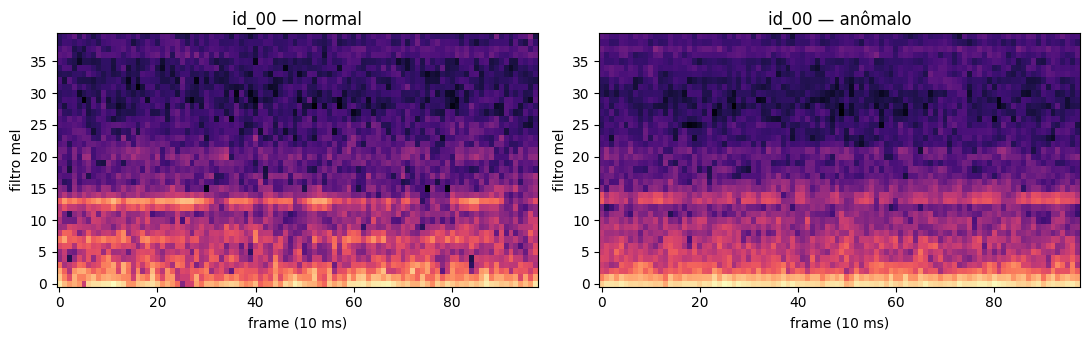

Forma da entrada da CNN: (98, 40)


In [9]:
# 6. Conferência visual: um clipe normal e um anômalo da mesma máquina
import zipfile, matplotlib.pyplot as plt
ex_n = inv[(inv.rotulo == 0)].iloc[0]; ex_a = inv[(inv.rotulo == 1) & (inv.maquina == ex_n.maquina)].iloc[0]
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.5))
with zipfile.ZipFile(ZIP) as z:
    for ax, ex, tit in zip(eixos, [ex_n, ex_a], ["normal", "anômalo"]):
        M = log_mel(janelas(ler_canal(z, ex.membro))[0])
        ax.imshow(M.T, origin="lower", aspect="auto", cmap="magma")
        ax.set_title(f"{ex.maquina} — {tit}"); ax.set_xlabel("frame (10 ms)"); ax.set_ylabel("filtro mel")
plt.tight_layout(); plt.show()
print("Forma da entrada da CNN:", M.shape)

In [10]:
# 7. Extração das janelas de 1 s e dos espectrogramas (10 a 20 min)
from tqdm.auto import tqdm
saida = {p: {"X": [], "y": [], "grupo": [], "janela": []} for p in ["treino", "validacao", "teste"]}
with zipfile.ZipFile(ZIP) as z:
    for gi, it in enumerate(tqdm(itens)):
        p = particao[it["membro"]]
        for k, w in enumerate(janelas(ler_canal(z, it["membro"]))):
            saida[p]["X"].append(log_mel(w).astype(np.float16))
            saida[p]["y"].append(it["rotulo"]); saida[p]["grupo"].append(gi); saida[p]["janela"].append(k)

for p, d in saida.items():
    X = np.stack(d["X"]); y = np.array(d["y"], np.int8)
    np.savez(f"{PASTA}/{p}.npz", X=X, y=y, grupo=np.array(d["grupo"], np.int32), janela=np.array(d["janela"], np.int8))
    print(f"{p:10s} {X.shape}  normal={int((y==0).sum())}  anômalo={int((y==1).sum())}")

  0%|          | 0/5550 [00:00<?, ?it/s]

treino     (38850, 98, 40)  normal=28520  anômalo=10330
validacao  (8320, 98, 40)  normal=6110  anômalo=2210
teste      (8330, 98, 40)  normal=6120  anômalo=2210


In [11]:
# 8. Normalização (estatísticas só do treino) e parâmetros do espectrograma para o firmware
import json
Xtr = np.load(f"{PASTA}/treino.npz")["X"].astype(np.float32)
media, desvio = float(Xtr.mean()), float(Xtr.std())
params = {"fs": FS, "janela_s": JANELA_S, "frame": FRAME, "hop": HOP, "nfft": NFFT, "n_mel": N_MEL,
          "fmin": FMIN, "fmax": FMAX, "n_frames": N_FRAMES, "eps": EPS, "canal": CANAL,
          "escala_mel": "HTK", "janela_fft": "Hann periódica", "potencia": "|X|^2", "log": "natural",
          "normalizacao": {"media": media, "desvio": desvio}, "snr_mimii": "6 dB", "semente_divisao": 42,
          "versoes": {"python": sys.version.split()[0], "numpy": np.__version__}}
json.dump(params, open(f"{PASTA}/params_espectrograma.json", "w"), indent=2, ensure_ascii=False)
np.save(f"{PASTA}/banco_mel.npy", BANCO); np.save(f"{PASTA}/hann.npy", HANN)
print(json.dumps(params["normalizacao"], indent=2)); del Xtr

{
  "media": -4.954929351806641,
  "desvio": 1.7134594917297363
}


In [12]:
# 9. Subconjunto de paridade: áudio bruto (int16) + espectrograma esperado
# Servirá para conferir, na placa, que o CMSIS-DSP produz o mesmo espectrograma do Python.
teste = inv[inv.particao == "teste"]
amostra = pd.concat([teste[teste.rotulo == 0].head(5), teste[teste.rotulo == 1].head(5)])
brutos, esperados = [], []
with zipfile.ZipFile(ZIP) as z:
    for _, it in amostra.iterrows():
        w = janelas(ler_canal(z, it.membro))[0]
        w16 = np.round(np.clip(w, -1, 1) * 32767).astype(np.int16)   # como o PDM entrega
        brutos.append(w16); esperados.append(log_mel(w16.astype(np.float32) / 32768.0))
np.savez(f"{PASTA}/paridade.npz", audio_int16=np.stack(brutos), logmel=np.stack(esperados),
         rotulo=amostra.rotulo.values, membro=amostra.membro.values)
print("Paridade salva:", np.stack(brutos).shape)

Paridade salva: (10, 16000)


## Resultado

No Drive, em `dissertacao_tinyml/mimii_fan_6db/`:

| Arquivo | Conteúdo |
|---|---|
| `treino.npz`, `validacao.npz`, `teste.npz` | `X` (n, 98, 40) float16, `y` (0 normal, 1 anômalo), `grupo` (gravação de origem) |
| `inventario_clipes.csv`, `particao_por_gravacao.csv` | rastreabilidade da divisão (guia de replicação) |
| `params_espectrograma.json`, `banco_mel.npy`, `hann.npy` | parâmetros e tabelas para o firmware |
| `paridade.npz` | 10 janelas de teste para validar o espectrograma na placa |

**Próximo notebook:** `02_treino_cnn.ipynb` — CNN 2D (8-16-32 filtros), cinco sementes, quantização int8.